# 02 · Engenharia de features

Uma linha por **cartão** (`gold/card_features`). Cada grupo nasce de uma hipótese de fraude e
**nenhuma feature usa rótulo**. As mesmas definições existem em PySpark
(`src/data_pipeline/spark/features_spark.py`), com teste de paridade.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if (Path.cwd().parent / "mlops").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SILVER = ROOT / "data/processed/silver"
GOLD = ROOT / "data/processed/gold"
REPORTS = ROOT / "mlops/reports"

In [2]:
from src import config
from src.models.explain import DESCRICOES
FEATURES = config.model_config()["features"]
feats = pd.read_parquet(GOLD / "card_features.parquet")
labels = pd.read_parquet(SILVER / "labels_cartao.parquet")[["card_id", "classe", "is_fraude", "tipos_fraude"]]
df = feats.merge(labels, on="card_id")
print(df.shape, "| features no modelo:", len(FEATURES))
df[FEATURES].describe().T.round(3)

(2500, 46) | features no modelo: 36


,count,mean,std,min,25%,50%,75%,max
embarques_por_dia_ativo,2500.0,2.111,0.066,1.977,2.058,2.068,2.173,2.409
pico_embarques_dia,2500.0,4.209,0.747,3.000,4.000,4.000,4.000,10.000
pct_dias_3mais_embarques,2500.0,0.105,0.058,0.035,0.057,0.066,0.164,0.333
pct_dias_ativos,2500.0,0.703,0.151,0.244,0.662,0.795,0.813,0.860
maior_sequencia_dias,2500.0,13.360,11.578,1.000,6.000,8.000,20.000,93.000
maior_hiato_dias,2500.0,72.253,128.138,4.000,5.000,6.000,12.000,426.000
n_operadoras,2500.0,2.336,1.354,1.000,1.000,2.000,3.000,6.000
n_linhas,2500.0,4.296,4.234,1.000,2.000,2.000,5.000,27.000
pct_linha_principal,2500.0,0.803,0.228,0.170,0.637,0.923,0.988,1.000
pct_intermunicipal,2500.0,0.003,0.009,0.000,0.000,0.000,0.000,0.128


## Poder de separação de cada feature

AUC univariada: 0,5 = não separa; distante de 0,5 (para cima ou para baixo) = separa.
É só diagnóstico — o rótulo **não** é usado para escolher o modelo de produção, que é não supervisionado.

In [3]:
from sklearn.metrics import roc_auc_score
auc = pd.Series({f: roc_auc_score(df.is_fraude, df[f]) for f in FEATURES}, name="auc")
sep = (auc.to_frame().assign(forca=lambda d: (d.auc - 0.5).abs(), descricao=lambda d: d.index.map(DESCRICOES))
       .sort_values("forca", ascending=False))
sep.head(15).round(3)

,auc,forca,descricao
pico_mensal_razao_embarques,0.825,0.325,pico mensal de uso vs. histórico
n_linhas,0.799,0.299,linhas diferentes
n_operadoras,0.776,0.276,operadoras diferentes
pico_mensal_pct_meio_dia,0.766,0.266,pior mês com uso no meio do dia
pct_troca_linha_mesmo_dia,0.755,0.255,troca de linha no mesmo dia
maior_sequencia_dias,0.727,0.227,maior sequência de dias seguidos com uso
pico_embarques_dia,0.687,0.187,maior nº de embarques num dia
pct_noite,0.676,0.176,embarques à noite
pico_mensal_pct_noite,0.671,0.171,pior mês com uso noturno
pct_reembarque_5min,0.657,0.157,reembarques em menos de 5 min


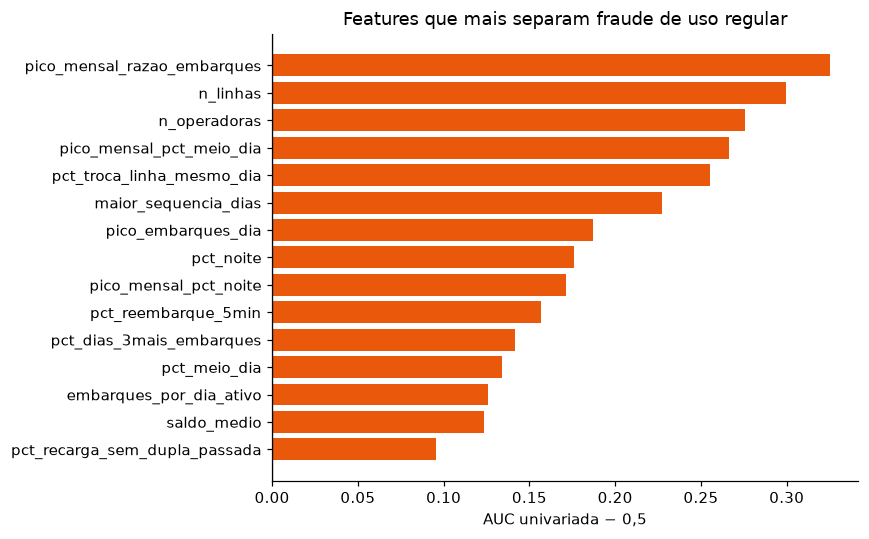

In [4]:
top = sep.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.auc - 0.5, color=np.where(top.auc > 0.5, "#EA580C", "#2563EB"))
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("AUC univariada − 0,5")
ax.set_title("Features que mais separam fraude de uso regular"); plt.tight_layout()

## Assinatura por tipo de fraude
Mediana de algumas features por tipo (cartões com um único tipo) contra os regulares.

In [5]:
chave = ["pct_replay", "pct_troca_operadora_15min", "pct_inconsistencia_saldo", "pct_tarifa_divergente",
         "pct_recarga_valor_redondo", "pct_recarga_sem_dupla_passada", "razao_recarga_consumo",
         "pico_mensal_fora_linha_principal", "pico_mensal_pct_meio_dia", "pico_mensal_pct_noite",
         "pct_intermunicipal", "maior_sequencia_dias", "pct_erro_leitura"]
unico = df[(df.is_fraude == 1) & ~df.tipos_fraude.str.contains("\\|")]
tab = unico.groupby("tipos_fraude")[chave].median()
tab.loc["(Regular)"] = df.loc[df.is_fraude == 0, chave].median()
(tab / tab.loc["(Regular)"].replace(0, np.nan)).round(1).fillna(tab.round(3))

,pct_replay,pct_troca_operadora_15min,pct_inconsistencia_saldo,pct_tarifa_divergente,pct_recarga_valor_redondo,pct_recarga_sem_dupla_passada,razao_recarga_consumo,pico_mensal_fora_linha_principal,pico_mensal_pct_meio_dia,pico_mensal_pct_noite,pct_intermunicipal,maior_sequencia_dias,pct_erro_leitura
tipos_fraude,,,,,,,,,,,,,
Clonagem,0.000,0.044,0.000,0.000,0.000,0.000,1.0,2.8,1.0,1.2,0.000,1.0,4.4
Conluio operacional,0.000,0.000,0.000,0.052,0.000,0.000,1.0,0.4,0.8,1.1,0.000,1.0,1.2
Desvio de finalidade,0.000,0.000,0.000,0.000,0.000,0.000,1.0,2.0,1.5,9.0,0.000,5.0,1.0
Empréstimo do cartão,0.000,0.000,0.000,0.000,0.000,0.000,1.0,2.0,3.1,0.9,0.000,9.2,1.0
Endereço falso,0.000,0.000,0.000,0.000,0.000,0.000,1.0,0.5,0.7,0.8,0.000,1.0,1.0
Recarga clandestina,0.000,0.000,0.000,0.000,0.116,0.109,1.0,3.7,1.1,1.1,0.000,2.2,1.0
Replay,0.026,0.000,0.000,0.000,0.000,0.000,1.0,2.4,1.2,1.1,0.000,1.0,1.0
Uso de gratuidade associado ao VT,0.000,0.000,0.000,0.000,0.000,0.000,1.0,3.1,1.1,1.1,0.000,1.0,1.1
Uso em férias,0.000,0.000,0.000,0.000,0.000,0.000,1.0,3.5,5.0,1.6,0.072,5.7,1.2


## Correlação entre features
Grupos muito correlacionados (ex.: volume) não atrapalham o Isolation Forest, mas pesam na leitura do SHAP.

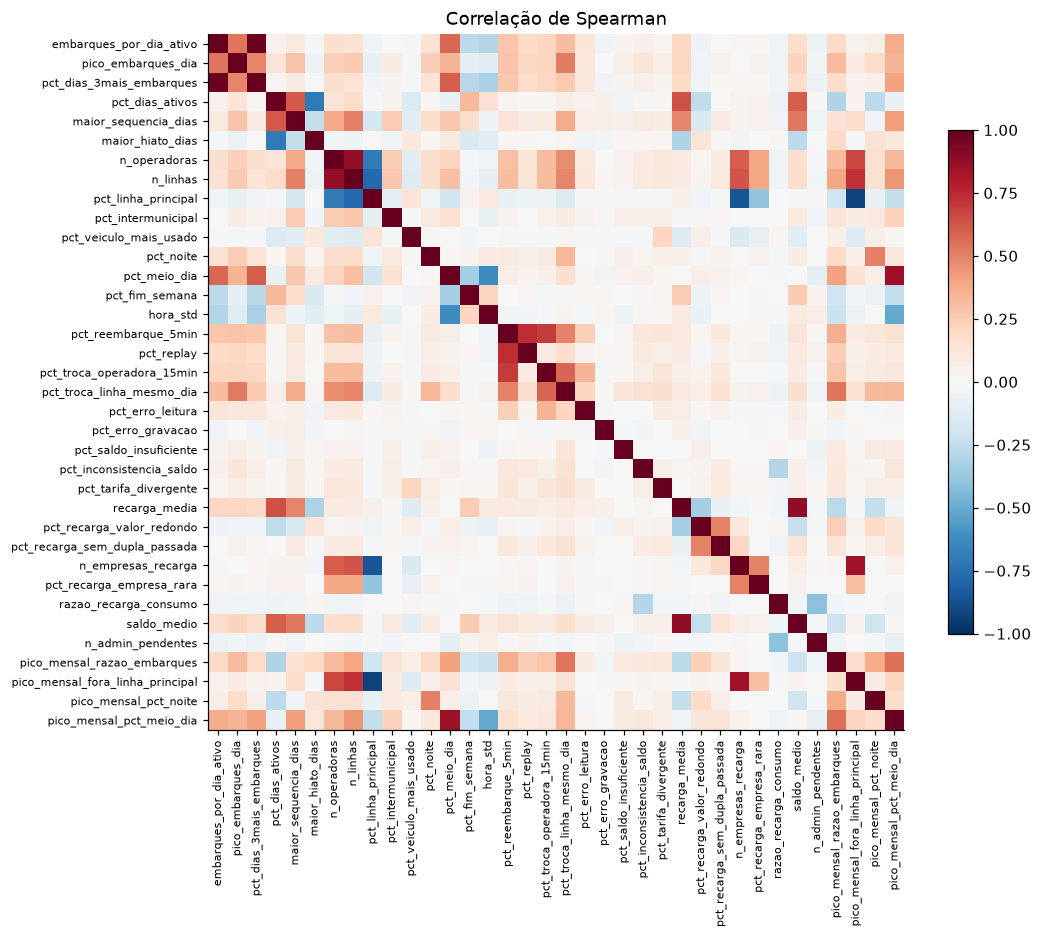

In [6]:
corr = df[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7); ax.set_title("Correlação de Spearman"); plt.tight_layout()

### Decisões

- **Picos mensais** superam médias de 5 anos: fraude ocorre em episódios.
- Proporções (`pct_*`) em vez de contagens, para não confundir fraude com cartão de uso intenso.
- Features de validador/saldo (`pct_inconsistencia_saldo`, `pct_recarga_sem_dupla_passada`) só existem porque a
  silver reconstrói a **continuidade do saldo** e a **dupla passada** — engenharia de dados virando sinal.